### Niha Batool
### Registration No: FA23-BAI-042



**Wine Quality Prediction Using Keras**

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models, regularizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)

In [4]:
# Load data directly from the UCI repository
url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "wine-quality/winequality-red.csv"
)

df = pd.read_csv(url, sep=";")

print(df.head())
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

In [5]:
# Separate input features and target quality score
X = df.drop("quality", axis=1).values
y = df["quality"].values

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardize features using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1279
Testing samples: 320


**Lab Task 1 — Build and train a neural network**

In [6]:
# Predict a numerical quality score using regression
model = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)  # One continuous output
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Train the neural network
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Evaluate on unseen test data
predictions = model.predict(X_test, verbose=0).flatten()

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Task 1 Results")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 26.0846 - mae: 4.9918 - val_loss: 16.9122 - val_mae: 3.9746
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 9.9991 - mae: 2.8684 - val_loss: 4.5630 - val_mae: 1.8113
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.4415 - mae: 1.4776 - val_loss: 2.6011 - val_mae: 1.2922
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.3775 - mae: 1.2114 - val_loss: 2.2524 - val_mae: 1.1962
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.9974 - mae: 1.1146 - val_loss: 2.0462 - val_mae: 1.1330
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.7842 - mae: 1.0520 - val_loss: 1.8857 - val_mae: 1.0852
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.6280 - mae: 1.0049 - val_loss: 1.7428 - val_mae: 1.0397
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.4987 - mae: 0.9649 - val_loss: 1.6145 - val_mae: 0.9984
Epoch 9/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.3859 - ma

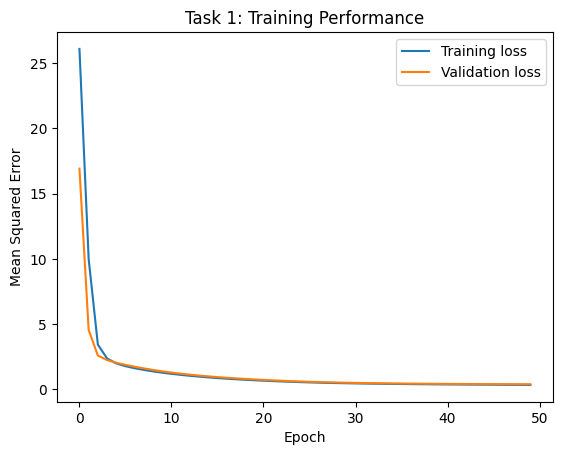

In [8]:
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Task 1: Training Performance")
plt.legend()
plt.show()

**Lab Task 2 — Improve neural network performance**

In [9]:
def build_model(neurons=64, dropout=0.0, l2_value=0.0):
    model = models.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(
            neurons,
            activation="relu",
            kernel_regularizer=regularizers.l2(l2_value)
        ),
        layers.Dropout(dropout),
        layers.Dense(neurons // 2, activation="relu"),
        layers.Dense(1)
    ])
    return model

In [10]:
experiments = [
    ("Baseline Adam", 64, 0.0, 0.0, "adam", 50, 32),
    ("Larger Adam", 128, 0.0, 0.0, "adam", 70, 32),
    ("Regularized Adam", 64, 0.2, 0.001, "adam", 70, 32),
    ("RMSprop", 64, 0.2, 0.001, "rmsprop", 70, 16),
    ("SGD Momentum", 64, 0.2, 0.001,
     tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
     70, 32)
]

results = []

for name, neurons, dropout, l2_value, optimizer, epochs, batch_size in experiments:
    # Reset model weights for each independent experiment
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    net = build_model(neurons, dropout, l2_value)

    net.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )

    net.fit(
        X_train, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.2,
        verbose=0
    )

    # Evaluate using the same held-out test set
    pred = net.predict(X_test, verbose=0).flatten()

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results)
print(results_df.round(3).to_string(index=False))

           Model   MAE  RMSE    R2
   Baseline Adam 0.494 0.619 0.414
     Larger Adam 0.501 0.640 0.374
Regularized Adam 0.478 0.599 0.450
         RMSprop 0.472 0.593 0.463
    SGD Momentum 0.461 0.601 0.448


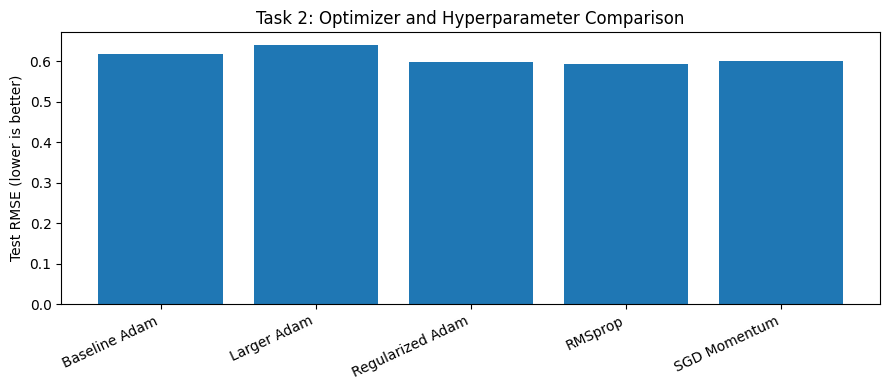

Best observed configuration: RMSprop
Best observed RMSE: 0.593


In [11]:
plt.figure(figsize=(9, 4))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.ylabel("Test RMSE (lower is better)")
plt.title("Task 2: Optimizer and Hyperparameter Comparison")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# Lowest test RMSE in this experiment
best = results_df.loc[results_df["RMSE"].idxmin()]
print("Best observed configuration:", best["Model"])
print("Best observed RMSE:", round(best["RMSE"], 3))

In [12]:
baseline = results_df[results_df["Model"] == "Baseline Adam"].iloc[0]
best = results_df.loc[results_df["RMSE"].idxmin()]

print(f"""
LAB TASK 1: WINE QUALITY PREDICTION

Preprocessing:
The red wine dataset contains physicochemical features and a
numerical quality score. The data was split into training and
testing sets. Input features were standardized using the training
data's mean and standard deviation.

Model:
The baseline neural network has two hidden layers with 64 and
32 ReLU neurons and one numerical output. Adam optimization and
mean squared error loss were used for regression. MAE, RMSE,
and R-squared were used for evaluation.

LAB TASK 2: PERFORMANCE IMPROVEMENT

Initial RMSE: {baseline['RMSE']:.3f}
Initial MAE: {baseline['MAE']:.3f}

Techniques:
Different neuron counts, epochs, batch sizes, dropout,
L2 regularization, Adam, RMSprop, and SGD with momentum
were compared.

Best observed model: {best['Model']}
Best observed RMSE: {best['RMSE']:.3f}
Best observed MAE: {best['MAE']:.3f}
Best observed R-squared: {best['R2']:.3f}

Observations:
Lower MAE and RMSE indicate more accurate predictions.
R-squared describes how much variation in quality scores
is explained by the predictions. Regularization may reduce
overfitting, but it does not guarantee better performance.
The experiment's measured results should guide the conclusion.

Conclusion:
Keras makes it straightforward to build and compare neural
networks. Suitable architecture and optimizer choices can
improve prediction performance, but results depend on the
data and hyperparameters.
""")


LAB TASK 1: WINE QUALITY PREDICTION

Preprocessing:
The red wine dataset contains physicochemical features and a
numerical quality score. The data was split into training and
testing sets. Input features were standardized using the training
data's mean and standard deviation.

Model:
The baseline neural network has two hidden layers with 64 and
32 ReLU neurons and one numerical output. Adam optimization and
mean squared error loss were used for regression. MAE, RMSE,
and R-squared were used for evaluation.

LAB TASK 2: PERFORMANCE IMPROVEMENT

Initial RMSE: 0.619
Initial MAE: 0.494

Techniques:
Different neuron counts, epochs, batch sizes, dropout,
L2 regularization, Adam, RMSprop, and SGD with momentum
were compared.

Best observed model: RMSprop
Best observed RMSE: 0.593
Best observed MAE: 0.472
Best observed R-squared: 0.463

Observations:
Lower MAE and RMSE indicate more accurate predictions.
R-squared describes how much variation in quality scores
is explained by the predictions.